In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Reading file: /content/mon_projet/image-proc-caption-analysis/cleaned_dataset/knowledge_base/instances.json

Statistics:
Images: 9907
Mean: 7.34
Median: 4.0
Max: 70


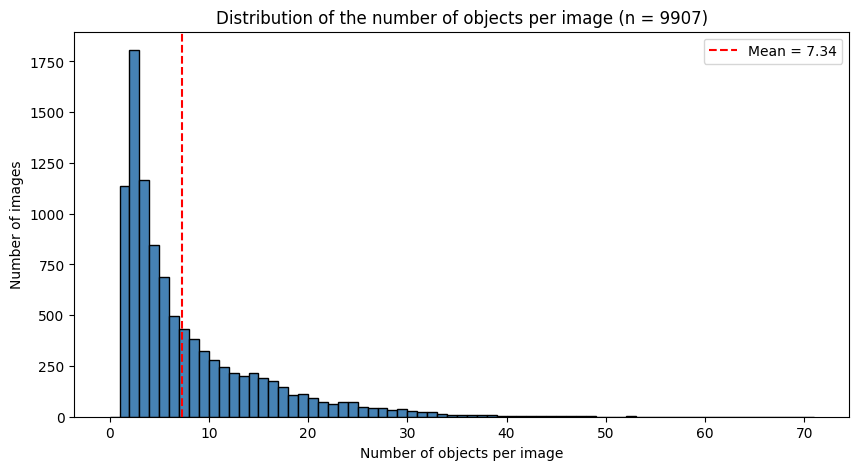

In [5]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Dossier où on a extrait le ZIP
dossier = '/content/mon_projet/image-proc-caption-analysis/cleaned_dataset/knowledge_base'
fichier = os.path.join(dossier, 'instances.json')

print("Reading file:", fichier)

# Ouverture du fichier JSON
with open(fichier, 'r') as f:
    data = json.load(f)

# On compte le nombre d'objets par image
compteur = Counter()
for ann in data['annotations']:
    compteur[ann['image_id']] += 1

# On transforme en tableau numpy pour les calculs
nb_objets = np.array(list(compteur.values()))

# Calculs des stats
moyenne = nb_objets.mean()
mediane = np.median(nb_objets)

print("\nStatistics:")
print("Images:", len(nb_objets))
print("Mean:", round(moyenne, 2))
print("Median:", mediane)
print("Max:", nb_objets.max())

# Création du graphique
plt.figure(figsize=(10, 5))
plt.hist(nb_objets, bins=range(0, int(nb_objets.max()) + 2), edgecolor='black', color='steelblue')
plt.axvline(moyenne, color='red', linestyle='--', label=f'Mean = {moyenne:.2f}')
plt.xlabel("Number of objects per image")
plt.ylabel("Number of images")
plt.title(f"Distribution of the number of objects per image (n = {len(nb_objets)})")
plt.legend()
plt.savefig('fig_objects_per_image.png', dpi=150)
plt.show()